# Multilevel Analysis for Retrospective Confidence based on Skin Conductance Response, Perceived Performance Perception, and Team Gameplay Score

by Elvis Ortega-Ochoa

In [153]:
import sys
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", "pip", "ipywidgets", "jupyterlab_widgets"])
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "pymer4",
    "rpy2",
    "polars",
    "great-tables",
    "joblib",
    "scikit-learn",
    "pyarrow",
    "bambi",
    "arviz",
    "matplotlib",
    "pandas",
    "numpy",
    "statsmodels",
])

0

Packages

In [154]:
import pandas as pd
import numpy as np
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pymer4.models as pm
import polars as pl
import ipywidgets as widgets
from pymer4.models import lmer as Lmer

Loading data

In [ ]:
# Reading files and printing columns
scr = pd.read_excel("../../confidence_SCR/stable_scr_events_UPD.xlsx", keep_default_na=False)     
cf = pd.read_excel("../../confidence_SCR/CONT_dependent_variables_confidence_E.xlsx", keep_default_na=False)

# Make a clean copy
scr = scr.copy()
cf = cf.copy()

# Extract participantID and sensorID from scrID
scr["participantID"] = scr["scrID"].str.extract(r"SCR_([^.]+)\.")
scr["sensorID"] = scr["scrID"].str.extract(r"\.([A-Z]{2})-EDA$")

# Merge the dataframes on groupID, participantID, and sensorID
dataset = scr.merge(
    cf,
    on=["groupID", "participantID", "sensorID"],
    how="inner"
)

# Rename columns for clarity
dataset = dataset.rename(columns={
    "realGamePeaks/m": "realGamePeaks_per_m",
    "realTutoPeaks/m": "realTutoPeaks_per_m",
    "realQuestionsPeaks/m": "realQuestionsPeaks_per_m",
    "realPitchPeaks/m": "realPitchPeaks_per_m",
    "CF1": "cf",
    "PP1": "pp"
})

Build questionPath as numeric

In [156]:
# Build numeric questionPath at group level
dataset["qBonusPeaks"] = pd.to_numeric(dataset["qBonusPeaks"], errors="coerce")
dataset["qPenaltyPeaks"] = pd.to_numeric(dataset["qPenaltyPeaks"], errors="coerce")

dataset["has_bonus"] = dataset["qBonusPeaks"].notna()
dataset["has_penalty"] = dataset["qPenaltyPeaks"].notna()

group_path = (
    dataset.groupby("groupID")[["has_bonus", "has_penalty"]]
    .any()
    .reset_index()
)

group_path["questionPath"] = np.select(
    [
        group_path["has_bonus"] & ~group_path["has_penalty"],
        group_path["has_penalty"] & ~group_path["has_bonus"],
    ],
    [1, 0],
    default=np.nan,
)

# Drop any existing questionPath variants to avoid suffixes, then merge
dataset = dataset.drop(columns=[c for c in dataset.columns if c.startswith("questionPath")], errors="ignore")
dataset = dataset.merge(group_path[["groupID", "questionPath"]], on="groupID", how="left")

Reverse team gameplay score

In [194]:
# Reverse-score uncertScore using the observed scale range
dataset["uncertScore"] = dataset["uncertScore"].max() + dataset["uncertScore"].min() - dataset["uncertScore"]

In [158]:
# Finalize data types
dataset["groupID"] = dataset["groupID"].astype("category")
dataset["cf"] = pd.to_numeric(dataset["cf"], errors="coerce")
dataset["questionPath"] = pd.Categorical(dataset["questionPath"], categories=[0,1])

In [159]:
# Keep just variables needed
dat_model = dataset[["groupID", "participantID", "cf", "pp", "uncertScore", "realGamePeaks_per_m", "realTutoPeaks_per_m", "realQuestionsPeaks_per_m", "realPitchPeaks_per_m", "questionPath", "pitchRole"]].copy()

## Mixed Linear Models

### Within/Between Descomposition

In [164]:

def add_within_between(df, raw_col, prefix):
    group_mean = df.groupby("groupID")[raw_col].transform("mean")
    within = df[raw_col] - group_mean
    between = group_mean - group_mean.mean()

    df[f"{prefix}_group_mean"] = group_mean
    df[f"{prefix}_within"] = within
    df[f"{prefix}_between"] = between

    return df

dat_model = add_within_between(dat_model, "realGamePeaks_per_m", "scr")
dat_model = add_within_between(dat_model, "realTutoPeaks_per_m", "tuto")
dat_model = add_within_between(dat_model, "realQuestionsPeaks_per_m", "questions")
dat_model = add_within_between(dat_model, "realPitchPeaks_per_m", "pitch")
dat_model = add_within_between(dat_model, "pp", "pp")

### Standarize predictor variables

In [165]:
dat_model["realGamePeaks_per_m_z"] = (
    dat_model["realGamePeaks_per_m"] - dat_model["realGamePeaks_per_m"].mean()
) / dat_model["realGamePeaks_per_m"].std()

dat_model["scr_within_z"] = (
    dat_model["scr_within"] - dat_model["scr_within"].mean()
) / dat_model["scr_within"].std()

dat_model["scr_between_z"] = (
    dat_model["scr_between"] - dat_model["scr_between"].mean()
) / dat_model["scr_between"].std()

dat_model["tuto_within_z"] = (
    dat_model["tuto_within"] - dat_model["tuto_within"].mean()
) / dat_model["tuto_within"].std()

dat_model["tuto_between_z"] = (
    dat_model["tuto_between"] - dat_model["tuto_between"].mean()
) / dat_model["tuto_between"].std()

dat_model["questions_within_z"] = (
    dat_model["questions_within"] - dat_model["questions_within"].mean()
) / dat_model["questions_within"].std()

dat_model["questions_between_z"] = (
    dat_model["questions_between"] - dat_model["questions_between"].mean()
) / dat_model["questions_between"].std()

dat_model["pitch_within_z"] = (
    dat_model["pitch_within"] - dat_model["pitch_within"].mean()
) / dat_model["pitch_within"].std()

dat_model["pitch_between_z"] = (
    dat_model["pitch_between"] - dat_model["pitch_between"].mean()
) / dat_model["pitch_between"].std()

dat_model["pp_z"] = (
    dat_model["pp"] - dat_model["pp"].mean()
) / dat_model["pp"].std()

dat_model["pp_within_z"] = (
    dat_model["pp_within"] - dat_model["pp_within"].mean()
) / dat_model["pp_within"].std()

dat_model["pp_between_z"] = (
    dat_model["pp_between"] - dat_model["pp_between"].mean()
) / dat_model["pp_between"].std()

dat_model["uncertScore_z"] = (
    dat_model["uncertScore"] - dat_model["uncertScore"].mean()
) / dat_model["uncertScore"].std()

dat_model.columns.tolist()

['groupID',
 'participantID',
 'cf',
 'pp',
 'uncertScore',
 'realGamePeaks_per_m',
 'realTutoPeaks_per_m',
 'realQuestionsPeaks_per_m',
 'realPitchPeaks_per_m',
 'questionPath',
 'pitchRole',
 'scr_group_mean',
 'scr_within',
 'scr_between',
 'tuto_group_mean',
 'tuto_within',
 'tuto_between',
 'questions_group_mean',
 'questions_within',
 'questions_between',
 'pitch_group_mean',
 'pitch_within',
 'pitch_between',
 'pp_group_mean',
 'pp_within',
 'pp_between',
 'realGamePeaks_per_m_z',
 'scr_within_z',
 'scr_between_z',
 'tuto_within_z',
 'tuto_between_z',
 'questions_within_z',
 'questions_between_z',
 'pitch_within_z',
 'pitch_between_z',
 'pp_z',
 'pp_within_z',
 'pp_between_z',
 'uncertScore_z']

Pitch data cleaning

In [168]:
dat_model['pitchRole'] = pd.to_numeric(dat_model['pitchRole'], errors='coerce')
dat_model_pitch_role = dat_model.dropna(subset=['groupID',
 'participantID',
 'cf',
 'pp',
 'uncertScore',
 'realGamePeaks_per_m',
 'realTutoPeaks_per_m',
 'realQuestionsPeaks_per_m',
 'realPitchPeaks_per_m',
 'questionPath',
 'pitchRole',
 'scr_group_mean',
 'scr_within',
 'scr_between',
 'tuto_group_mean',
 'tuto_within',
 'tuto_between',
 'questions_group_mean',
 'questions_within',
 'questions_between',
 'pitch_group_mean',
 'pitch_within',
 'pitch_between',
 'pp_group_mean',
 'pp_within',
 'pp_between',
 'realGamePeaks_per_m_z',
 'scr_within_z',
 'scr_between_z',
 'tuto_within_z',
 'tuto_between_z',
 'questions_within_z',
 'questions_between_z',
 'pitch_within_z',
 'pitch_between_z',
 'pp_z',
 'pp_within_z',
 'pp_between_z',
 'uncertScore_z']).copy()

dat_model_pitch_role = dat_model_pitch_role[dat_model_pitch_role['pitchRole'].isin([0, 1])].copy()

# Finalize data type
dat_model_pitch_role["pitchRole"] = pd.Categorical(dat_model_pitch_role["pitchRole"], categories=[0, 1])

## Exploratory Data Analysis

Missing values:
cf                          0
pp                          0
uncertScore                 0
realGamePeaks_per_m         0
realTutoPeaks_per_m         0
realQuestionsPeaks_per_m    0
realPitchPeaks_per_m        0
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
cf,87.0,3.425287,1.559906,1.000000,2.000000,3.000000,5.000000,7.000000
pp,87.0,6.494253,1.764466,2.000000,5.000000,7.000000,8.000000,10.000000
uncertScore,87.0,47.482759,7.603338,25.000000,44.000000,48.000000,51.000000,60.000000
realGamePeaks_per_m,87.0,2.114204,2.406057,-4.070671,0.358493,2.079011,3.722039,8.403172
realTutoPeaks_per_m,87.0,2.989865,2.548684,-3.124891,1.270447,2.378785,5.282077,8.361345
realQuestionsPeaks_per_m,87.0,1.800861,2.490374,-4.446577,0.189259,1.723939,3.370871,9.234457
realPitchPeaks_per_m,87.0,2.272550,3.905028,-11.221374,0.346963,2.019637,4.973874,9.502378


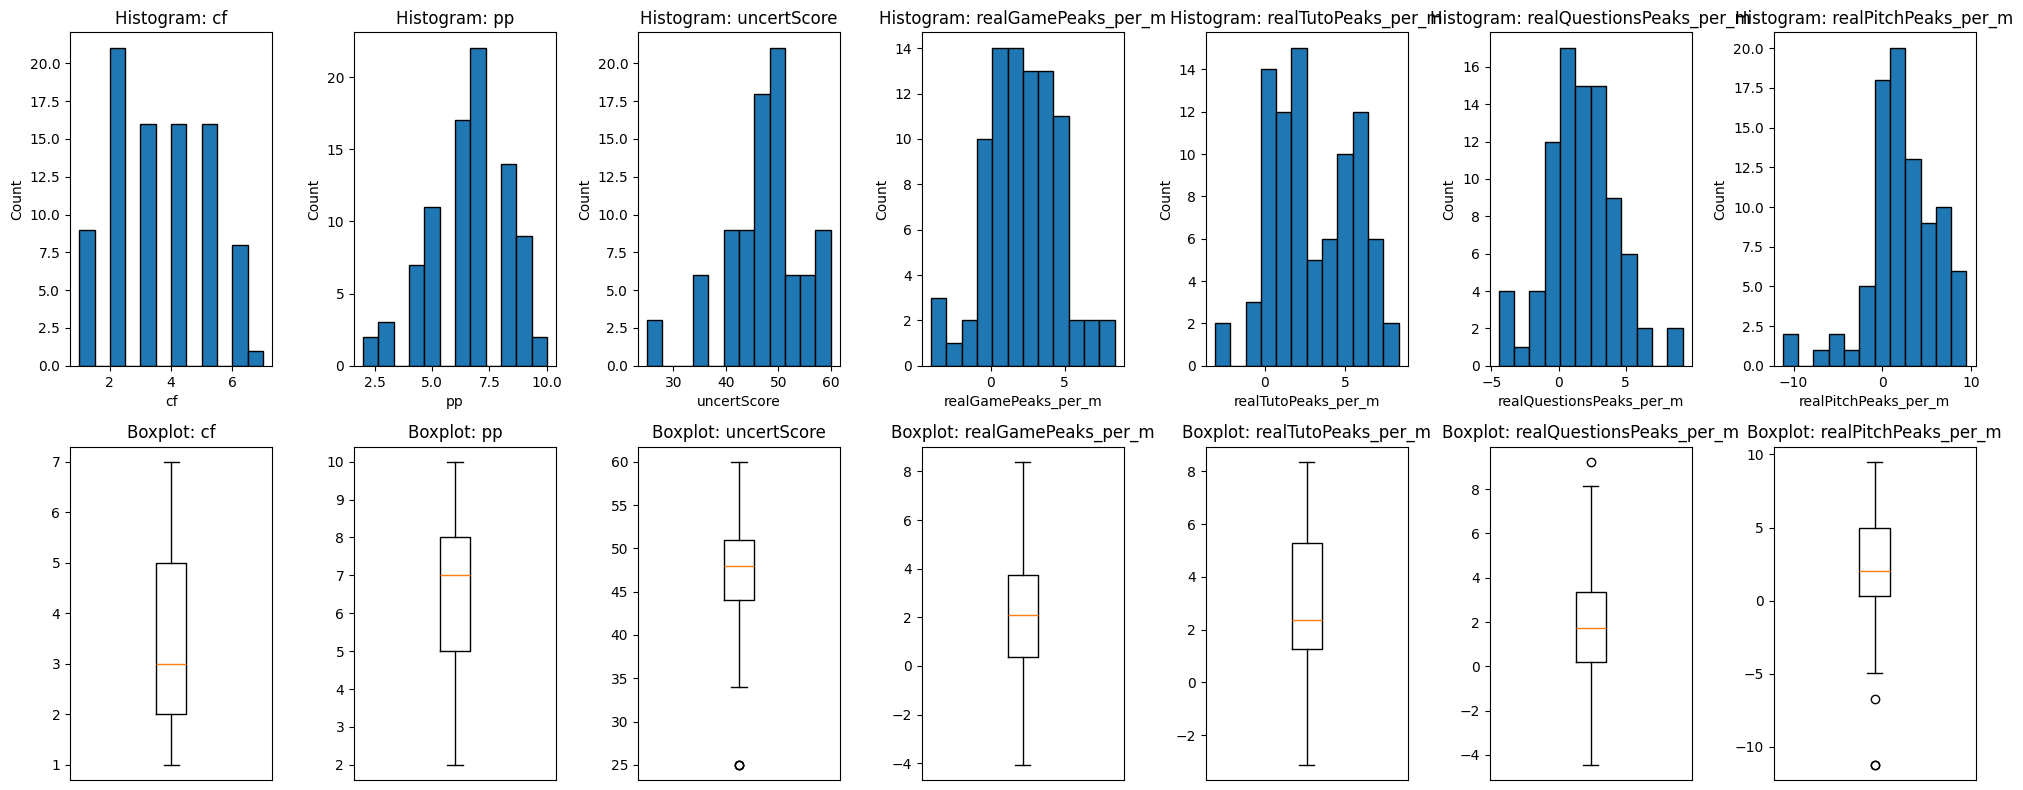

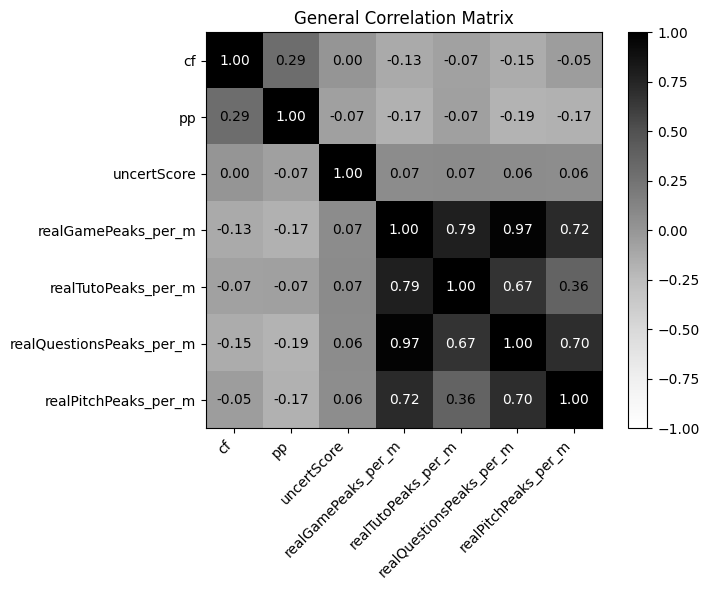

In [232]:
cols = ["cf", "pp", "uncertScore", "realGamePeaks_per_m", "realTutoPeaks_per_m", "realQuestionsPeaks_per_m", "realPitchPeaks_per_m"]

# Basic summary
print("Missing values:")
print(dat_model[cols].isna().sum(), "\n")

print("Descriptive statistics:")
display(dat_model[cols].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols), figsize=(20, 8))

for i, col in enumerate(cols):
    axes[0, i].hist(dat_model[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(dat_model[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

# Correlation matrix
corr = dat_model[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)
ax.set_title("General Correlation Matrix")

# Add correlation scores in each cell
for i in range(len(cols)):
    for j in range(len(cols)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=text_color)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [234]:
eda_df = dat_model.copy()

eda_df[["pitch_within", "pitch_between"]] = np.nan
eda_df.loc[dat_model_pitch_role.index, ["pitch_within", "pitch_between"]] = dat_model_pitch_role[["pitch_within", "pitch_between"]].to_numpy()

cols_within_between = ["cf", "pp_within", "uncertScore", "scr_within", "tuto_within", "questions_within", "pitch_within", "pp_between", "scr_between",  "tuto_between", "questions_between", "pitch_between"]
cols_within = ["cf", "pp_within", "uncertScore", "scr_within", "tuto_within", "questions_within", "pitch_within"]
cols_between = ["cf", "pp_between", "uncertScore", "scr_between",  "tuto_between", "questions_between", "pitch_between"]

Within-team Exploratory Data Analysis

Missing values:
cf                  0
pp_within           0
uncertScore         0
scr_within          0
tuto_within         0
questions_within    0
pitch_within        3
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
cf,87.0,3.425287e+00,1.559906,1.000000,2.000000,3.000000,5.000000,7.000000
pp_within,87.0,-5.104474e-17,1.275895,-2.666667,-1.000000,0.000000,1.000000,3.333333
uncertScore,87.0,4.748276e+01,7.603338,25.000000,44.000000,48.000000,51.000000,60.000000
scr_within,87.0,4.083579e-17,1.952139,-4.228912,-1.186685,0.079387,1.136715,4.572771
tuto_within,87.0,1.020895e-17,2.049427,-3.827188,-1.513568,-0.096863,1.860652,4.003711
questions_within,87.0,-1.786566e-17,1.992601,-4.223753,-1.400472,0.153288,1.088501,5.281570
pitch_within,84.0,-1.057355e-17,3.098589,-9.181356,-1.706938,-0.176149,2.024036,10.406666


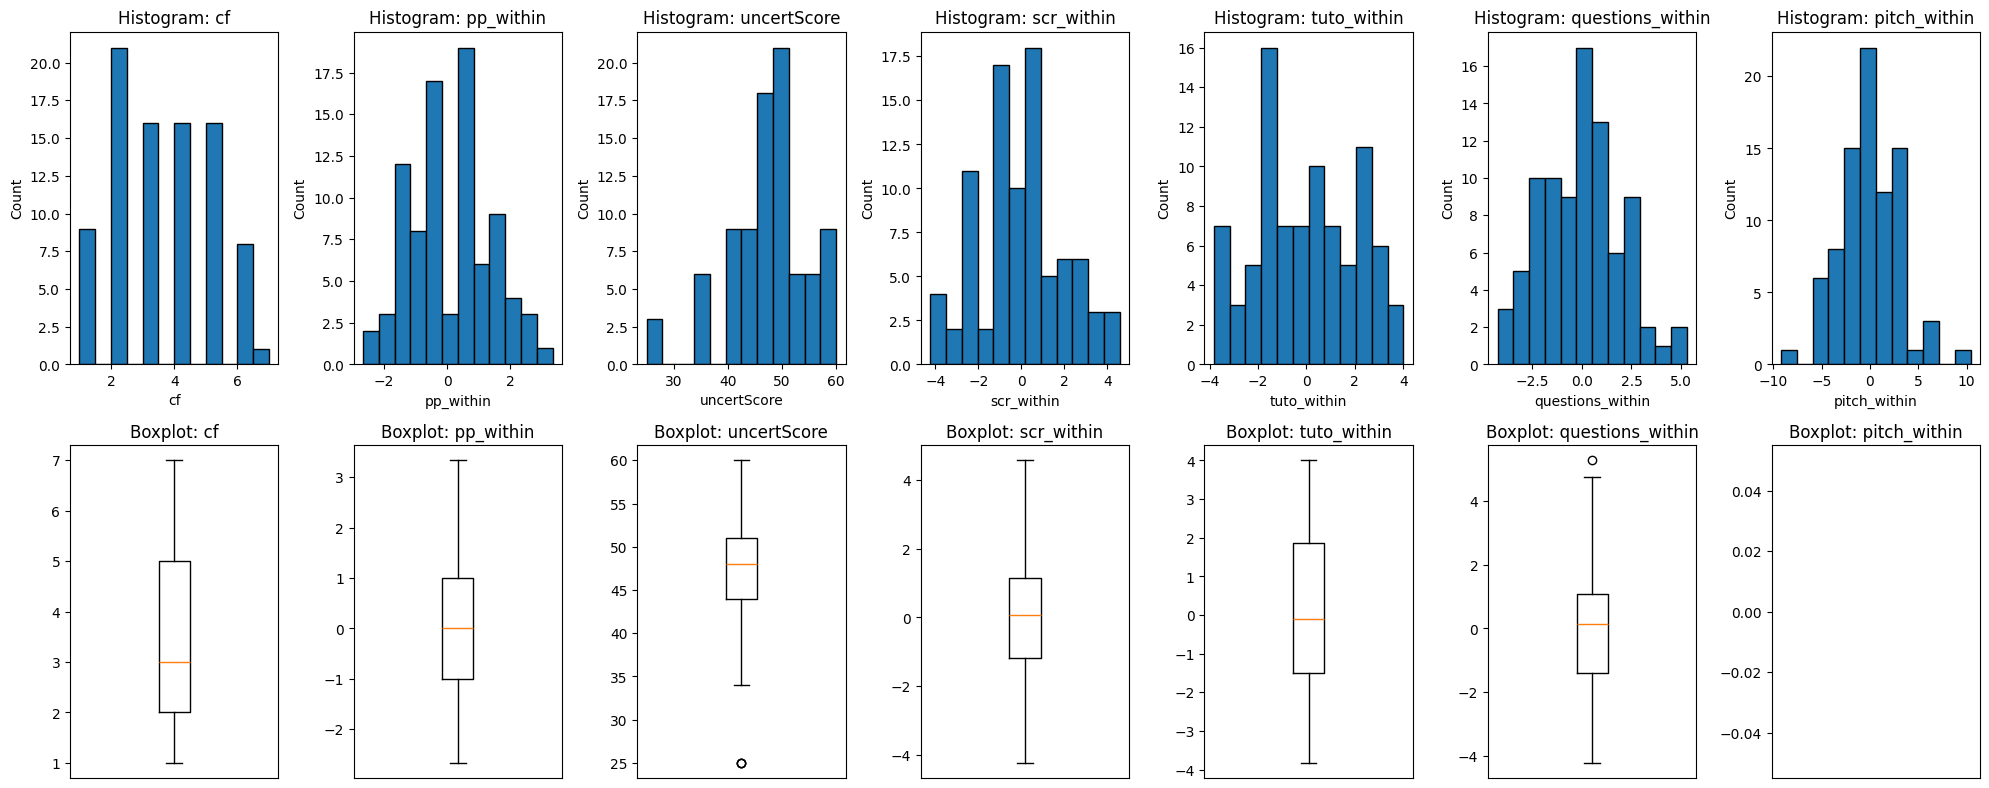

In [226]:
# Basic summary
print("Missing values:")
print(eda_df[cols_within].isna().sum(), "\n")

print("Descriptive statistics:")
display(eda_df[cols_within].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols_within), figsize=(20, 8))

for i, col in enumerate(cols_within):
    axes[0, i].hist(eda_df[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(eda_df[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

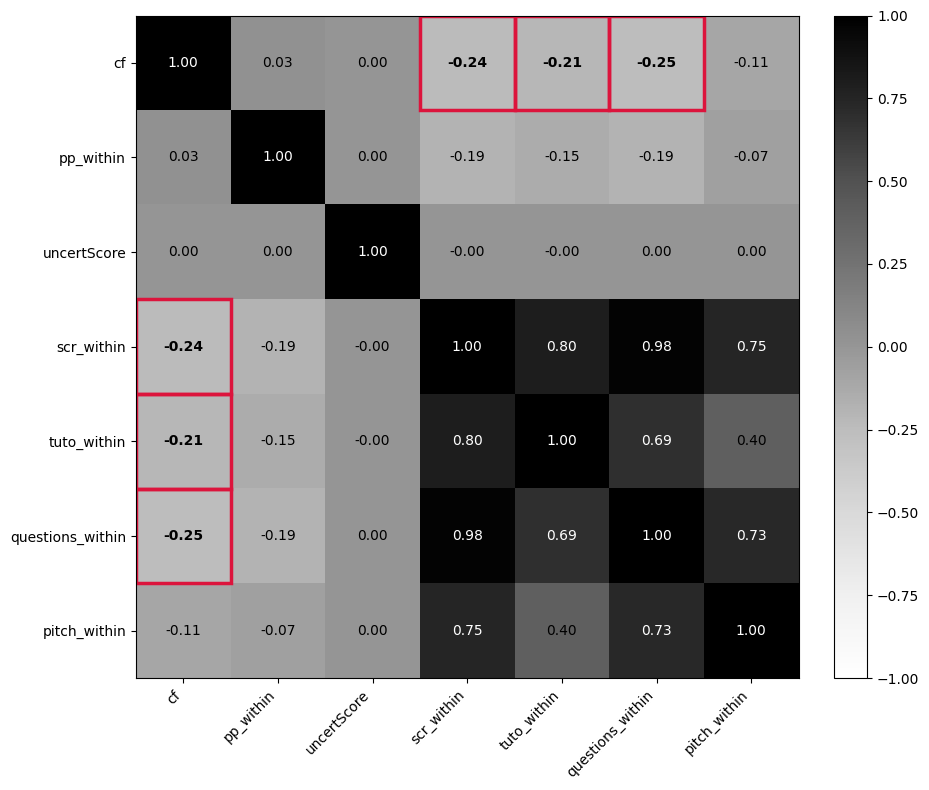

In [ ]:
# Correlation matrix
corr = eda_df[cols_within].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

ax.set_xticks(range(len(cols_within)))
ax.set_yticks(range(len(cols_within)))
ax.set_xticklabels(cols_within, rotation=45, ha="right")
ax.set_yticklabels(cols_within)

threshold = 0.20
focus_var = "cf"

for i in range(len(cols_within)):
    for j in range(len(cols_within)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_within[i], cols_within[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

Between-team Exploratory Data Analysis

Missing values:
cf                   0
pp_between           0
uncertScore          0
scr_between          0
tuto_between         0
questions_between    0
pitch_between        3
dtype: int64 

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
cf,87.0,3.425287e+00,1.559906,1.000000,2.000000,3.000000,5.000000,7.000000
pp_between,87.0,-1.327163e-16,1.218783,-2.827586,-0.827586,0.172414,0.839080,2.839080
uncertScore,87.0,4.748276e+01,7.603338,25.000000,44.000000,48.000000,51.000000,60.000000
scr_between,87.0,2.756416e-16,1.406507,-3.337750,-0.941966,-0.065864,0.914374,2.494181
tuto_between,87.0,-8.473426e-16,1.515138,-3.478591,-1.187725,0.369232,0.947484,2.792636
questions_between,87.0,8.167158e-17,1.493821,-3.056665,-1.009198,-0.114830,1.106064,2.363263
pitch_between,84.0,1.269501e-01,2.385979,-8.290591,-0.652798,0.139819,1.189454,4.415574


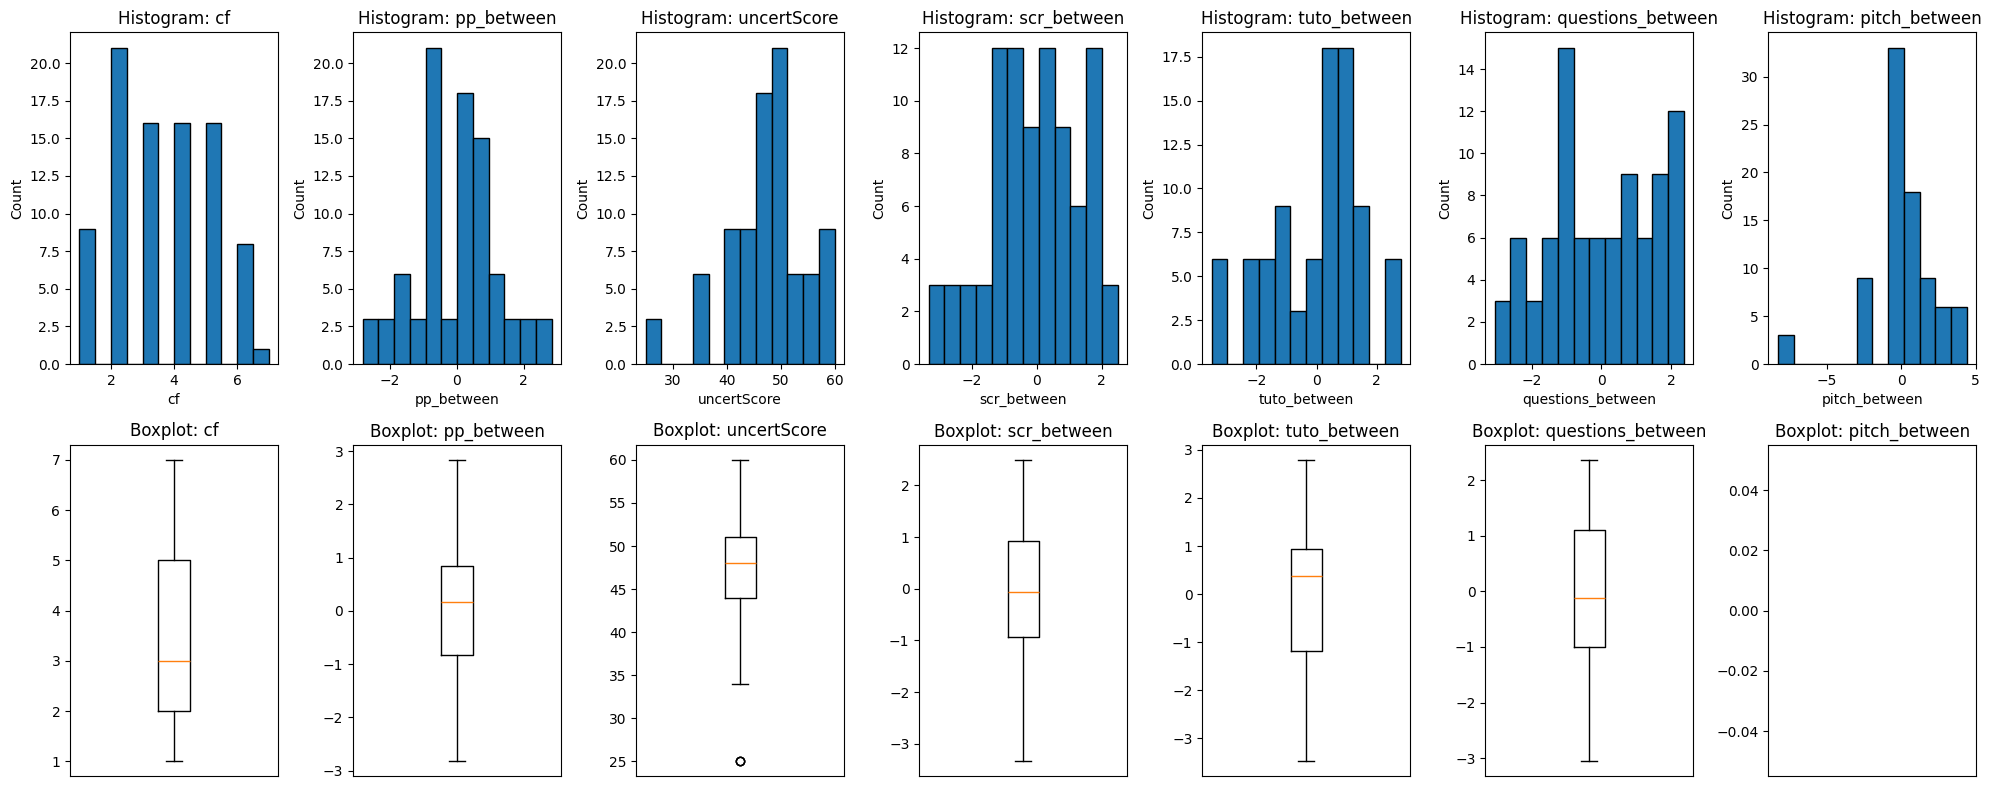

In [228]:
# Basic summary
print("Missing values:")
print(eda_df[cols_between].isna().sum(), "\n")

print("Descriptive statistics:")
display(eda_df[cols_between].describe().T)

# Distribution plots and boxplots
fig, axes = plt.subplots(2, len(cols_between), figsize=(20, 8))

for i, col in enumerate(cols_between):
    axes[0, i].hist(eda_df[col], bins=12, edgecolor="black")
    axes[0, i].set_title(f"Histogram: {col}")
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("Count")

    axes[1, i].boxplot(eda_df[col], vert=True)
    axes[1, i].set_title(f"Boxplot: {col}")
    axes[1, i].set_xticks([])

plt.tight_layout()
plt.show()

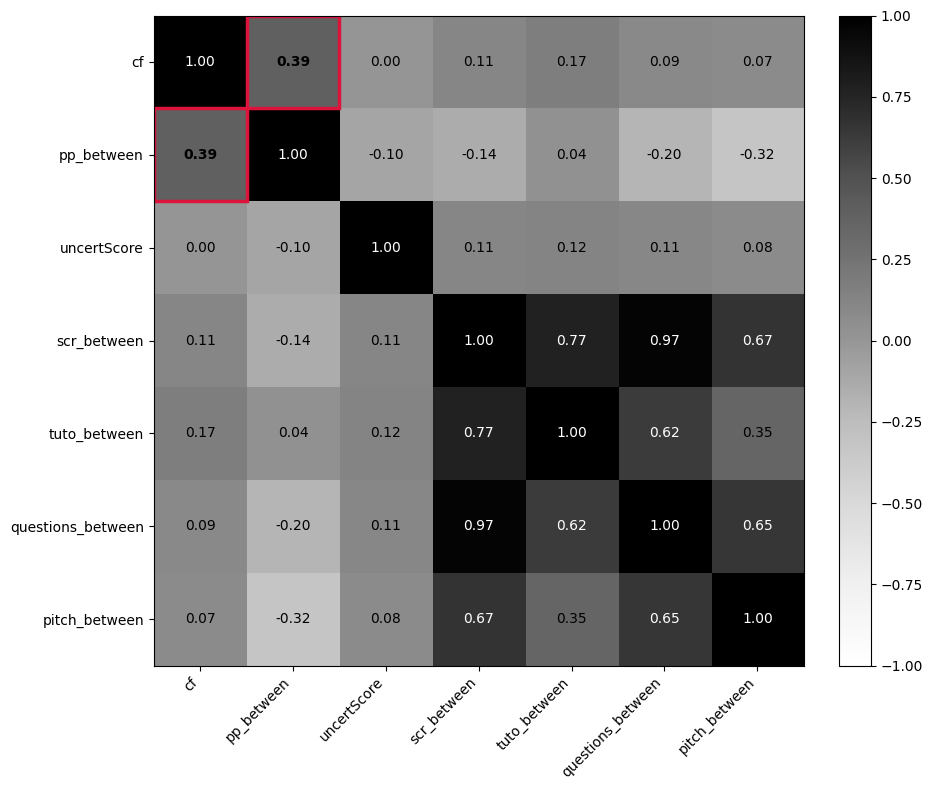

In [ ]:
# Correlation matrix
corr = eda_df[cols_between].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

ax.set_xticks(range(len(cols_between)))
ax.set_yticks(range(len(cols_between)))
ax.set_xticklabels(cols_between, rotation=45, ha="right")
ax.set_yticklabels(cols_between)
#ax.set_title("Detailed Correlation Matrix")

threshold = 0.20
focus_var = "cf"

for i in range(len(cols_between)):
    for j in range(len(cols_between)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_between[i], cols_between[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect) Ah, wait, wait, wait, wait, wait, wait, wait, wait, one note dies dies

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

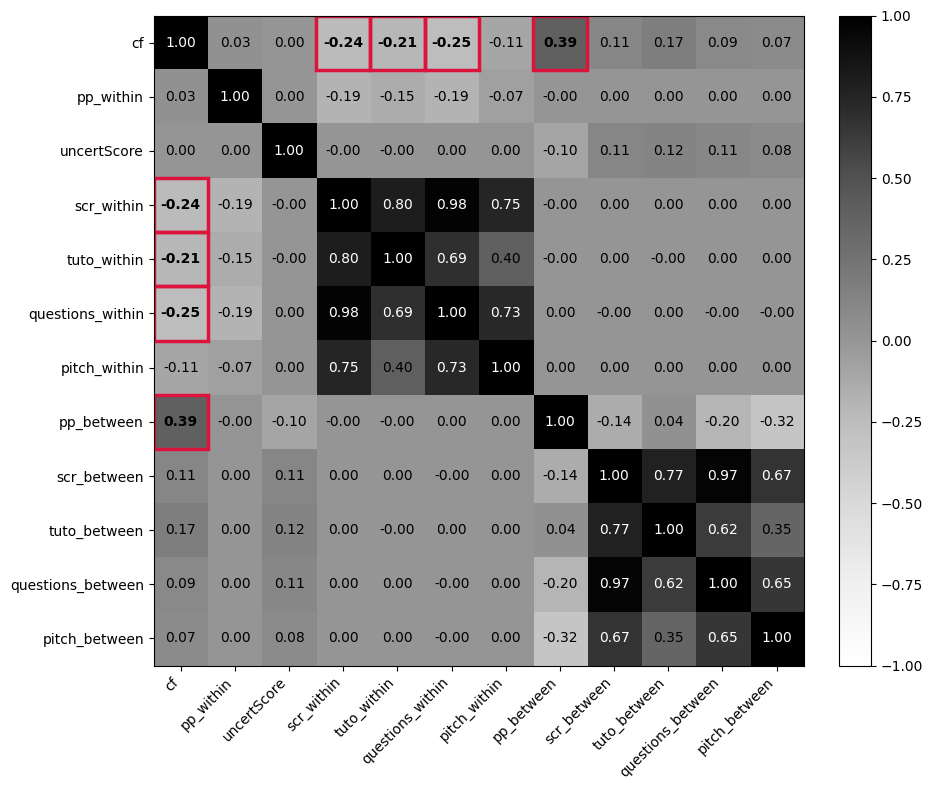

In [235]:
# Correlation matrix
corr = eda_df[cols_within_between].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

ax.set_xticks(range(len(cols_within_between)))
ax.set_yticks(range(len(cols_within_between)))
ax.set_xticklabels(cols_within_between, rotation=45, ha="right")
ax.set_yticklabels(cols_within_between)

threshold = 0.20
focus_var = "cf"

for i in range(len(cols_within_between)):
    for j in range(len(cols_within_between)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.5 else "black"
        involves_focus = focus_var in (cols_within_between[i], cols_within_between[j])
        is_strong = abs(value) >= threshold and i != j and involves_focus
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color=text_color, fontweight="bold" if is_strong else "normal")
        if is_strong:
            rect = patches.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       linewidth=2.5, edgecolor="crimson", facecolor="none")
            ax.add_patch(rect)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### Model 1 - Game play SCR: CF ~ realGamePeaks_per_m_z + (1|groupID)

1. Statsmodels (LME4)

In [ ]:
model1_sm = sm.MixedLM.from_formula(
    "cf ~ realGamePeaks_per_m_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result1_sm = model1_sm.fit(reml=False, method="lbfgs")
print("Model 1 sm: CF ~ realGamePeaks_per_m_z + (1|groupID)")
print(result1_sm.summary())

Model 1 sm: CF1 ~ realGamePeaks_per_m_z + (1|groupID)
             Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    cf       
No. Observations:    87         Method:                ML       
No. Groups:          29         Scale:                 1.8430   
Min. group size:     3          Log-Likelihood:        -159.0847
Max. group size:     3          Converged:             Yes      
Mean group size:     3.0                                        
----------------------------------------------------------------
                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept              3.425    0.199 17.230 0.000  3.036  3.815
realGamePeaks_per_m_z -0.294    0.165 -1.780 0.075 -0.618  0.030
groupID Var            0.532    0.281                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [171]:
model1_bmb = bmb.Model(
    "cf ~ realGamePeaks_per_m_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1 = model1_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 1 bmb: CF ~ realGamePeaks_per_m_z + (1|groupID)")
az.summary(idata_model1, var_names=["realGamePeaks_per_m_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, realGamePeaks_per_m_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Model 1 bmb: CF ~ realGamePeaks_per_m_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
realGamePeaks_per_m_z,-0.293,0.174,-0.606,0.042,0.002,0.002,5495.0,4901.0,1.0
1|groupID_sigma,0.727,0.277,0.149,1.217,0.007,0.004,1695.0,1804.0,1.0
sigma,1.405,0.134,1.172,1.670,0.003,0.002,2684.0,3775.0,1.0


#### Within/Between Model 1: CF ~ scr_within_z + scr_between_z + (1|groupID)

1. Statsmodels (LME4)

In [172]:
model1_within_sm = sm.MixedLM.from_formula(
    "cf ~ scr_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result1_within_sm = model1_within_sm.fit(reml=False, method="lbfgs")
print("Model 1 within sm: CF ~ scr_within_z + (1|groupID)")
print(result1_within_sm.summary())

Model 1 within sm: CF ~ scr_within_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: cf       
No. Observations: 87      Method:             ML       
No. Groups:       29      Scale:              1.8161   
Min. group size:  3       Log-Likelihood:     -157.4809
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     3.425    0.191 17.944 0.000  3.051  3.799
scr_within_z -0.374    0.145 -2.570 0.010 -0.658 -0.089
groupID Var   0.451    0.252                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [173]:
model1_between_sm = sm.MixedLM.from_formula(
    "cf ~ scr_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result1_between_sm = model1_between_sm.fit(reml=False, method="lbfgs")
print("Model 1 between sm: CF ~ scr_between_z + (1|groupID)")
print(result1_between_sm.summary())

Model 1 between sm: CF ~ scr_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: cf       
No. Observations: 87      Method:             ML       
No. Groups:       29      Scale:              2.0230   
Min. group size:  3       Log-Likelihood:     -160.1800
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     3.425    0.188 18.212 0.000  3.057  3.794
scr_between_z 0.177    0.189  0.934 0.350 -0.194  0.547
groupID Var   0.351    0.232                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [174]:
model1_within_bmb  = bmb.Model(
    "cf ~ scr_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1_within_bmb = model1_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 1 within bmb: CF ~ scr_within_z + (1|groupID)")
az.summary(idata_model1_within_bmb, var_names=["scr_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, scr_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
There were 64 divergences after tuning. Increase `target_accept` or reparameterize.


Model 1 within bmb: CF ~ scr_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
scr_within_z,-0.371,0.153,-0.660,-0.085,0.002,0.002,4811.0,4477.0,1.0
1|groupID_sigma,0.644,0.272,0.059,1.098,0.007,0.004,1451.0,1908.0,1.0
sigma,1.399,0.132,1.175,1.658,0.003,0.002,2406.0,3769.0,1.0


In [175]:
model1_between_bmb  = bmb.Model(
    "cf ~ scr_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model1_between_bmb = model1_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 1 between bmb: CF ~ scr_between_z + (1|groupID)")
az.summary(idata_model1_between_bmb, var_names=["scr_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, scr_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 125 divergences after tuning. Increase `target_accept` or reparameterize.


Model 1 between bmb: CF ~ scr_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
scr_between_z,0.178,0.202,-0.195,0.559,0.004,0.003,2548.0,2894.0,1.0
1|groupID_sigma,0.618,0.282,0.018,1.058,0.008,0.004,1335.0,2450.0,1.0
sigma,1.459,0.134,1.207,1.706,0.003,0.002,2018.0,1676.0,1.0


### Model 2 - Event Phase: CF ~ event_phase_within/between_z + (1|groupID)

#### a) Tutorial

1. Statsmodels (LME4)

In [176]:
model2_tuto_within_sm = sm.MixedLM.from_formula(
    "cf ~ tuto_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result2_tuto_within_sm = model2_tuto_within_sm.fit(reml=False, method="lbfgs")
print("Model 2 tuto within sm: CF ~ tuto_within_z + (1|groupID)")
print(result2_tuto_within_sm.summary())

Model 2 tuto within sm: CF ~ tuto_within_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: cf       
No. Observations:  87      Method:             ML       
No. Groups:        29      Scale:              1.8608   
Min. group size:   3       Log-Likelihood:     -158.1856
Max. group size:   3       Converged:          Yes      
Mean group size:   3.0                                  
--------------------------------------------------------
              Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------
Intercept      3.425    0.191 17.944 0.000  3.051  3.799
tuto_within_z -0.331    0.147 -2.249 0.025 -0.619 -0.042
groupID Var    0.436    0.249                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [178]:
model2_tuto_within_bmb  = bmb.Model(
    "cf ~ tuto_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_tuto_within_bmb = model2_tuto_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 2 tuto within bmb: CF ~ tuto_within_z + (1|groupID)")
az.summary(idata_model2_tuto_within_bmb, var_names=["tuto_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, tuto_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


Model 2 tuto within bmb: CF ~ tuto_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tuto_within_z,-0.328,0.154,-0.603,-0.023,0.002,0.002,10489.0,5413.0,1.0
1|groupID_sigma,0.652,0.276,0.030,1.084,0.007,0.004,1566.0,1696.0,1.0
sigma,1.413,0.132,1.177,1.663,0.002,0.002,3233.0,4309.0,1.0


#### b) Questions

1. Statsmodels (LME4)

In [179]:
model2_questions_within_sm = sm.MixedLM.from_formula(
    "cf ~ questions_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result2_questions_within_sm = model2_questions_within_sm.fit(reml=False, method="lbfgs")
print("Model 2 questions within sm: CF ~ questions_within_z + (1|groupID)")
print(result2_questions_within_sm.summary())

Model 2 questions within sm: CF ~ questions_within_z + (1|groupID)
            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   cf       
No. Observations:   87        Method:               ML       
No. Groups:         29        Scale:                1.7918   
Min. group size:    3         Log-Likelihood:       -157.0901
Max. group size:    3         Converged:            Yes      
Mean group size:    3.0                                      
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           3.425    0.191 17.944 0.000  3.051  3.799
questions_within_z -0.395    0.144 -2.736 0.006 -0.678 -0.112
groupID Var         0.459    0.254                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [180]:
model2_questions_within_bmb  = bmb.Model(
    "cf ~ questions_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model2_questions_within_bmb = model2_questions_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 2 questions within bmb: CF ~ questions_within_z + (1|groupID)")
az.summary(idata_model2_questions_within_bmb, var_names=["questions_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, questions_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
There were 52 divergences after tuning. Increase `target_accept` or reparameterize.


Model 2 questions within bmb: CF ~ questions_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
questions_within_z,-0.396,0.152,-0.697,-0.123,0.002,0.003,4089.0,2600.0,1.0
1|groupID_sigma,0.659,0.267,0.119,1.144,0.008,0.004,1099.0,2147.0,1.0
sigma,1.389,0.131,1.147,1.625,0.003,0.002,1587.0,1906.0,1.0


#### c) Pitch

1. Statsmodels (LME4)

In [181]:
model2_pitch_within_sm = sm.MixedLM.from_formula(
    "cf ~ pitch_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model_pitch_role
)
result2_pitch_within_sm = model2_pitch_within_sm.fit(reml=False, method="lbfgs")
print("Model 2 pitch within sm: CF ~ pitch_within_z + (1|groupID)")
print(result2_pitch_within_sm.summary())

Model 2 pitch within sm: CF ~ pitch_within_z + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: cf       
No. Observations:   84      Method:             ML       
No. Groups:         28      Scale:              1.8982   
Min. group size:    3       Log-Likelihood:     -153.7519
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       3.417    0.198 17.299 0.000  3.030  3.804
pitch_within_z -0.166    0.149 -1.117 0.264 -0.458  0.125
groupID Var     0.460    0.260                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [182]:
model2_pitch_within_bmb  = bmb.Model(
    "cf ~ pitch_within_z + (1|groupID)",
    data=dat_model_pitch_role,
    family="gaussian"
)

idata_model2_pitch_within_bmb = model2_pitch_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 2 pitch within bmb: CF ~ pitch_within_z + (1|groupID)")
az.summary(idata_model2_pitch_within_bmb, var_names=["pitch_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, pitch_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 187 divergences after tuning. Increase `target_accept` or reparameterize.


Model 2 pitch within bmb: CF ~ pitch_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
pitch_within_z,-0.166,0.156,-0.457,0.137,0.002,0.002,5687.0,4425.0,1.0
1|groupID_sigma,0.655,0.279,0.071,1.128,0.008,0.003,1315.0,2591.0,1.0
sigma,1.425,0.144,1.169,1.700,0.004,0.003,1159.0,576.0,1.0


### Model 3 - Performance Perception: CF ~ pp_within/between_z + (1|groupID)

1. Statsmodels (LME4)

In [185]:
model3_pp_within_sm = sm.MixedLM.from_formula(
    "cf ~ pp_within_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result3_pp_within_sm = model3_pp_within_sm.fit(reml=False, method="lbfgs")
print("Model 3 pp within sm: CF ~ pp_within_z + (1|groupID)")
print(result3_pp_within_sm.summary())

Model 3 pp within sm: CF ~ pp_within_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: cf       
No. Observations: 87      Method:             ML       
No. Groups:       29      Scale:              2.0190   
Min. group size:  3       Log-Likelihood:     -160.5529
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     3.425    0.191 17.944 0.000  3.051  3.799
pp_within_z   0.052    0.153  0.337 0.736 -0.249  0.352
groupID Var   0.384    0.239                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


In [184]:
model3_pp_between_sm = sm.MixedLM.from_formula(
    "cf ~ pp_between_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result3_pp_between_sm = model3_pp_between_sm.fit(reml=False, method="lbfgs")
print("Model 3 pp between sm: CF ~ pp_between_z + (1|groupID)")
print(result3_pp_between_sm.summary())

Model 3 pp between sm: CF ~ pp_between_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: cf       
No. Observations: 87      Method:             ML       
No. Groups:       29      Scale:              2.0230   
Min. group size:  3       Log-Likelihood:     -154.6185
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     3.425    0.155 22.062 0.000  3.121  3.730
pp_between_z  0.601    0.156  3.852 0.000  0.295  0.908
groupID Var   0.025    0.158                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [186]:
model3_pp_within_bmb  = bmb.Model(
    "cf ~ pp_within_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model3_pp_within_bmb = model3_pp_within_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 3 pp within bmb: CF ~ pp_within_z + (1|groupID)")
az.summary(idata_model3_pp_within_bmb, var_names=["pp_within_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, pp_within_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 7 divergences after tuning. Increase `target_accept` or reparameterize.


Model 3 pp within bmb: CF ~ pp_within_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
pp_within_z,0.053,0.161,-0.264,0.352,0.002,0.002,8566.0,4592.0,1.0
1|groupID_sigma,0.598,0.280,0.000,1.025,0.007,0.003,1536.0,1928.0,1.0
sigma,1.468,0.135,1.230,1.729,0.002,0.002,2934.0,2569.0,1.0


In [187]:
model3_pp_between_bmb  = bmb.Model(
    "cf ~ pp_between_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model3_pp_between_bmb = model3_pp_between_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 3 pp between bmb: CF ~ pp_between_z + (1|groupID)")
az.summary(idata_model3_pp_between_bmb, var_names=["pp_between_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, pp_between_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


Model 3 pp between bmb: CF ~ pp_between_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
pp_between_z,0.598,0.173,0.256,0.902,0.002,0.002,6958.0,4482.0,1.0
1|groupID_sigma,0.354,0.229,0.000,0.735,0.005,0.003,1989.0,3436.0,1.0
sigma,1.426,0.116,1.217,1.650,0.002,0.001,5567.0,4545.0,1.0


### Model 4 - Uncertainty Score: CF ~ uncertScore + (1|groupID)

1. Statsmodels (LME4)

In [188]:
model4_sm = sm.MixedLM.from_formula(
    "cf ~ uncertScore_z",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
result4_sm = model4_sm.fit(reml=False, method="lbfgs")
print("Model 4 sm: CF ~ uncertScore_z + (1|groupID)")
print(result4_sm.summary())

Model 4 sm: CF ~ uncertScore_z + (1|groupID)
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: cf       
No. Observations: 87      Method:             ML       
No. Groups:       29      Scale:              2.0230   
Min. group size:  3       Log-Likelihood:     -160.6093
Max. group size:  3       Converged:          Yes      
Mean group size:  3.0                                  
-------------------------------------------------------
              Coef. Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept     3.425    0.191 17.944 0.000  3.051  3.799
uncertScore_z 0.005    0.192  0.025 0.980 -0.371  0.381
groupID Var   0.382    0.239                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [189]:
model4_bmb  = bmb.Model(
    "cf ~ uncertScore_z + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_model4_bmb = model4_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model 4 bmb: CF ~ uncertScore_z + (1|groupID)")
az.summary(idata_model4_bmb, var_names=["uncertScore_z", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, uncertScore_z, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There were 65 divergences after tuning. Increase `target_accept` or reparameterize.


Model 4 bmb: CF ~ uncertScore_z + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
uncertScore_z,0.008,0.199,-0.359,0.391,0.003,0.003,3722.0,3405.0,1.0
1|groupID_sigma,0.633,0.284,0.043,1.096,0.008,0.003,1366.0,2465.0,1.0
sigma,1.462,0.135,1.208,1.714,0.003,0.002,2735.0,3195.0,1.0


### Follow-up models

#### Model Follow-up 1 Questions Path: CF ~ questionPath + (1|groupID)

1. Statsmodels (LME4)

In [191]:
modelFU1_sm = sm.MixedLM.from_formula(
    "cf ~ questionPath",
    groups="groupID",
    re_formula="1",
    data=dat_model
)
resultFU1_sm = modelFU1_sm.fit(reml=False, method="lbfgs")
print("Model FU1 sm: CF ~ questionPath + (1|groupID)")
print(resultFU1_sm.summary())

Model FU1 sm: CF ~ questionPath + (1|groupID)
           Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  cf       
No. Observations:    87       Method:              ML       
No. Groups:          29       Scale:               2.0230   
Min. group size:     3        Log-Likelihood:      -160.4384
Max. group size:     3        Converged:           Yes      
Mean group size:     3.0                                    
------------------------------------------------------------
                  Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept          3.500    0.229 15.317 0.000  3.052  3.948
questionPath[T.1] -0.241    0.410 -0.587 0.557 -1.045  0.563
groupID Var        0.370    0.236                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [190]:
modelFU1_bmb  = bmb.Model(
    "cf ~ questionPath + (1|groupID)",
    data=dat_model,
    family="gaussian"
)

idata_modelFU1_bmb = modelFU1_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model FU1 bmb: CF ~ questionPath + (1|groupID)")
az.summary(idata_modelFU1_bmb, var_names=["questionPath", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, questionPath, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 2 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


Model FU1 bmb: CF ~ questionPath + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
questionPath[1],-0.235,0.446,-1.102,0.570,0.006,0.006,5145.0,4421.0,1.0
1|groupID_sigma,0.636,0.281,0.044,1.102,0.007,0.004,1480.0,1968.0,1.0
sigma,1.457,0.135,1.224,1.722,0.002,0.002,2903.0,2909.0,1.0


#### Model Follow-up 2 PitchRole: CF ~ pitchRole + (1|groupID)

1. Statsmodels (LME4)

In [192]:
modelFU2_sm = sm.MixedLM.from_formula(
    "cf ~ pitchRole",
    groups="groupID",
    re_formula="1",
    data=dat_model_pitch_role
)
resultFU2_sm = modelFU2_sm.fit(reml=False, method="lbfgs")
print("Model FU2 sm: CF ~ pitchRole + (1|groupID)")
print(resultFU2_sm.summary())

Model FU2 sm: CF ~ pitchRole + (1|groupID)
          Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: cf       
No. Observations:   84      Method:             ML       
No. Groups:         28      Scale:              1.8618   
Min. group size:    3       Log-Likelihood:     -152.7906
Max. group size:    3       Converged:          Yes      
Mean group size:    3.0                                  
---------------------------------------------------------
               Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept       3.735    0.263 14.180 0.000  3.219  4.251
pitchRole[T.1] -0.582    0.324 -1.794 0.073 -1.217  0.054
groupID Var     0.439    0.254                           



/Users/elvisortegaec/Downloads/elvis_analysis/.venv/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


2. Bambi (Robustness testing)

In [193]:
modelFU2_bmb  = bmb.Model(
    "cf ~ pitchRole + (1|groupID)",
    data=dat_model_pitch_role,
    family="gaussian"
)

idata_modelFU2_bmb = modelFU2_bmb.fit(
    draws=2000,
    tune=2000,
    chains=4,
    cores=4,
    random_seed=123
)

print("Model FU2 bmb: CF ~ pitchRole + (1|groupID)")
az.summary(idata_modelFU2_bmb, var_names=["pitchRole", "1|groupID_sigma", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, pitchRole, 1|groupID_sigma, 1|groupID_offset]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
There were 16 divergences after tuning. Increase `target_accept` or reparameterize.


Model FU2 bmb: CF ~ pitchRole + (1|groupID)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
pitchRole[1],-0.586,0.339,-1.198,0.063,0.004,0.004,7782.0,5197.0,1.0
1|groupID_sigma,0.650,0.279,0.081,1.138,0.007,0.003,1623.0,2278.0,1.0
sigma,1.416,0.136,1.163,1.667,0.003,0.002,2869.0,3509.0,1.0
